In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [3]:
df = pd.read_csv('titanic_toy.csv')

In [4]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       714 non-null    float64
 1   Fare      846 non-null    float64
 2   Family    891 non-null    int64  
 3   Survived  891 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 28.0 KB


In [6]:
df.isnull().mean()

Age         0.198653
Fare        0.050505
Family      0.000000
Survived    0.000000
dtype: float64

In [7]:
x = df.drop(columns=['Survived'])
y = df['Survived']

In [8]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)    

In [9]:
mean_age = x_train['Age'].mean()
median_age = x_train['Age'].median()

mean_Fare = x_train['Fare'].mean()
median_Fare = x_train['Fare'].median()

x_train.shape, x_test.shape


((712, 3), (179, 3))

In [10]:
x_train['Age_mean'] = x_train['Age'].fillna(mean_age)
x_train['Age_median'] = x_train['Age'].fillna(median_age)

x_train['Fare_mean'] = x_train['Fare'].fillna(mean_Fare)
x_train['Fare_median'] = x_train['Fare'].fillna(median_Fare)

In [11]:
x_train.sample(5)

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
393,23.0,113.2750,1,23.000000,23.0,113.2750,113.2750
160,44.0,16.1000,1,44.000000,44.0,16.1000,16.1000
595,36.0,24.1500,2,36.000000,36.0,24.1500,24.1500
697,NaN,7.7333,0,29.498846,28.0,7.7333,7.7333
173,21.0,7.9250,0,21.000000,21.0,7.9250,7.9250


In [12]:
print('Orginal Age variable variance:', x_train['Age'].var())
print('Age variance after mean imputaion:', x_train['Age_mean'].var())
print('Age variance after median imputation:', x_train['Age_median'].var())

print('Orginal Fare variable variance:', x_train['Fare'].var())
print('Fare variance after mean imputaion:', x_train['Fare_mean'].var())
print('Fare variance after median imputation:', x_train['Fare_median'].var())

Orginal Age variable variance: 210.2517072477435
Age variance after mean imputaion: 168.85193366872227
Age variance after median imputation: 169.20731007048155
Orginal Fare variable variance: 2761.0314349486343
Fare variance after mean imputaion: 2621.232374951235
Fare variance after median imputation: 2637.012481677765


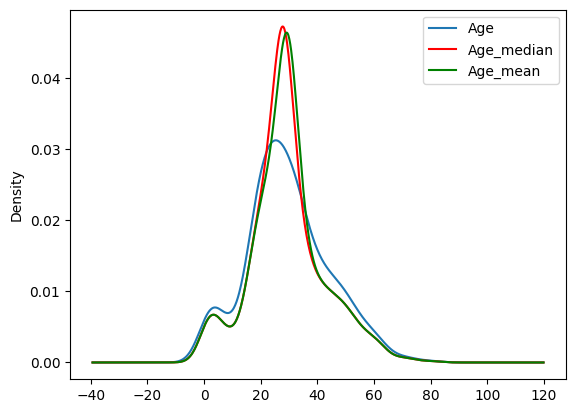

In [13]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original variable distribution
x_train['Age'].plot(kind='kde', ax=ax)

# variable imputed with the median
x_train['Age_median'].plot(kind='kde', ax=ax, color='red')

# variable imputed with the mean
x_train['Age_mean'].plot(kind='kde', ax=ax, color='green')

# add legends
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')


In [14]:
x_train.cov()

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
Age,210.251707,75.481375,-6.993325,210.251707,210.251707,71.193767,70.082085
Fare,75.481375,2761.031435,18.599163,60.224654,63.938058,2761.031435,2761.031435
Family,-6.993325,18.599163,2.830892,-5.616299,-5.587710,17.657433,17.672035
Age_mean,210.251707,60.224654,-5.616299,168.851934,168.851934,57.175304,56.282518
Age_median,210.251707,63.938058,-5.587710,168.851934,169.207310,60.700688,59.728510
Fare_mean,71.193767,2761.031435,17.657433,57.175304,60.700688,2621.232375,2621.232375
Fare_median,70.082085,2761.031435,17.672035,56.282518,59.728510,2621.232375,2637.012482


In [15]:
x_train.corr()

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
Age,1.000000,0.091482,-0.319651,1.000000,1.000000,0.088944,0.087232
Fare,0.091482,1.000000,0.207193,0.088151,0.093496,1.000000,1.000000
Family,-0.319651,0.207193,1.000000,-0.256883,-0.255307,0.204981,0.204536
Age_mean,1.000000,0.088151,-0.256883,1.000000,0.998949,0.085941,0.084346
Age_median,1.000000,0.093496,-0.255307,0.998949,1.000000,0.091145,0.089416
Fare_mean,0.088944,1.000000,0.204981,0.085941,0.091145,1.000000,0.997003
Fare_median,0.087232,1.000000,0.204536,0.084346,0.089416,0.997003,1.000000


<Axes: >

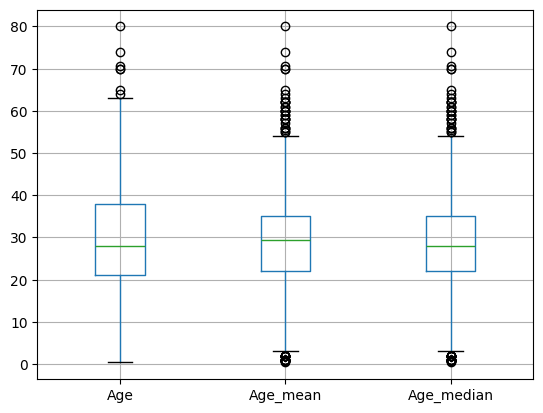

In [16]:
x_train[['Age', 'Age_mean', 'Age_median']].boxplot()


<Axes: >

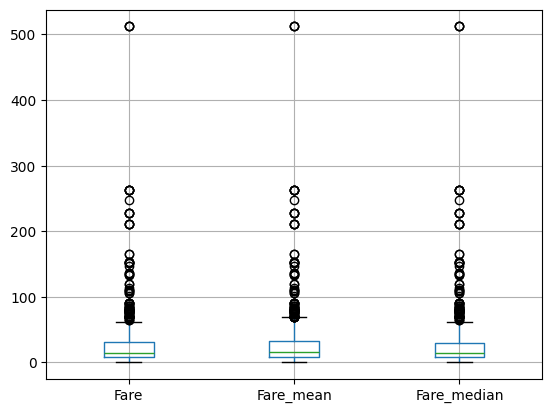

In [17]:
x_train[['Fare', 'Fare_mean', 'Fare_median']].boxplot()

## Using Sklearn

In [18]:
x_train, x_test, y_train, y_test = train_test_split(x,y, random_state=42, test_size=0.2)

In [19]:
imputer1 = SimpleImputer(strategy='median')
imputer2 = SimpleImputer(strategy='mean')


In [20]:
trf = ColumnTransformer([
    ('imputer1' ,imputer1,['Age']),
    ('imputer2' ,imputer2,['Fare'])

],remainder='passthrough')

In [21]:
trf.fit(x_train)

,transformers,"[('imputer1', ...), ('imputer2', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [22]:
trf.named_transformers_['imputer1'].statistics_

array([28.])

In [23]:
trf.named_transformers_['imputer2'].statistics_

array([32.51778772])

In [24]:
x_train = trf.transform(x_train)
x_test = trf.transform(x_test)

In [25]:
x_train

array([[ 45.5       ,  28.5       ,   0.        ],
       [ 23.        ,  13.        ,   0.        ],
       [ 32.        ,   7.925     ,   0.        ],
       ...,
       [ 41.        ,  32.51778772,   2.        ],
       [ 14.        , 120.        ,   3.        ],
       [ 21.        ,  77.2875    ,   1.        ]], shape=(712, 3))